# The closed form and the grid

> [!summary]
> The perfect foresight consumption model with CRRA utility has a consumption function in closed form, $c(m) = \kappa\,(m - L)$, with the marginal propensity to consume $\kappa = 1 - q$, the return patience factor $q = (R\beta)^{1/\rho}/R$, human wealth $h = 1/(1 - \Gamma/R)$ and the natural borrowing limit $L = 1 - h$ (`economics.md` of this folder). This notebook binds the stage file in two ways, shows the stage after each step of `elaborate → methodize → calibrate → configure`, and compares them. The closed-form route reads the consumption function, the two values and their marginals from the compiled kernels of the explicit blocks of `methods.bl` and checks them against the stage file's own blocks. The gridded route iterates the endogenous grid method of the replacing selection `methods.egm.bl` on the compiled kernels of its lines and reaches the closed form up to its tolerance. The notebook constructs, evaluates and solves; it writes nothing.

The package constructs the stages and binds their methods, calibration and settings; the module `closed_form_check.py` beside this notebook solves, evaluating only the equations the package compiles, and supplies the scalar Linear and PCHIP evaluators the comparisons use. The functions of the module whose names begin with `reference_` are the closed form of `economics.md` written in Python, test references against which the compiled kernels are compared.

The notebook reads these files:

`applications/consumption-perfect-foresight-crra/declaration/stages/perfect_foresight/perfect_foresight.bl`
`applications/consumption-perfect-foresight-crra/declaration/stages/perfect_foresight/methods.bl`
`applications/consumption-perfect-foresight-crra/declaration/stages/perfect_foresight/methods.egm.bl`
`applications/consumption-perfect-foresight-crra/declaration/calibration/perfect_foresight.yml`
`applications/consumption-perfect-foresight-crra/code/closed_form_check.py`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import closed_form_check as check

## The stage file

The stage sends human wealth backward as a constant field. It takes `h[>]`, computes `h = 1 + h[>]`, and sends `h[<] = h*Γ/R`. The feasible set is `0 < c < m + h[>]`. The stage defines only `q` as a derived parameter. Its discount factor lies in `ℝ₊₊ @ (0, R^(ρ-1))`, which states return impatience. Its growth factor lies in `ℝ₊₊`. The closed-form methods impose `Γ < R` through the positive declared set of `h_lim`; the grid methods do not impose it.


In [2]:
print(open(check.STAGE, encoding="utf-8").read())

@stage: perfect_foresight

# Perfect foresight consumption with human wealth sent backward.
# The decision field h includes this period's income; h[>] is the present
# value of the next period's human wealth. The stage sends h*Γ/R backward.
# The last period takes in zero. Feasibility reads h[>], with bound -h[>].

Xm := ℝ
Xa := ℝ

β : ℝ₊₊ @ (0, R^(ρ-1))   :: ["discount factor; its upper bound R^(ρ-1) is the return impatience condition, q < 1"]
ρ : (1, inf)               :: ["coefficient of relative risk aversion, greater than one"]
R : ℝ₊₊                    :: ["gross interest factor"]
Γ : ℝ₊₊                    :: ["permanent income growth factor"]

q : (0,1) := (β*R)^(1/ρ)/R   :: ["the return patience factor; the return impatience condition is q < 1"]

𝑢(c : ℝ₊₊) := c^(1-ρ)/(1-ρ)         :: [id=util]

Γ_c(x : Xm) := {c : ℝ₊₊ | c < x + h[>]}   :: [id=feasible_consumption]

[id=arvl_to_dcsn, (k : Xa) : !arvl -> (m : Xm) : !dcsn] {
    m = R*k/Γ + 1                   :: [id=market_res

## The closed-form route, step by step

`elaborate` reads the stage file. Its symbolic parameter table has four declared parameters and the derived return patience factor `q`. Methodization adds `κ`, `h_lim` and `L_lim`.


In [3]:
closed = check.elaborated()

In [4]:
closed.par

name  set                      value    describes
β     ℝ₊₊ @ (0, R^(ρ - 1))     unbound  discount factor; its upper bound R^(ρ-1) is the return impatience condition, q < 1
ρ     (1, inf)                 unbound  coefficient of relative risk aversion, greater than one
R     ℝ₊₊                      unbound  gross interest factor
Γ     ℝ₊₊                      unbound  permanent income growth factor
q     (0, 1) := (β*R)^(1/ρ)/R  unbound  the return patience factor; the return impatience condition is q < 1

The addition `methods.bl` types `!explicit` on the policy builder and on the two value builders. The line of each block writes its output as an explicit function of the state of its own perch: the consumption function, the decision value and the arrival value. Each value block also writes its marginal in closed form, the derivative of its value with respect to the state of its perch, since a representation offers a derivative only where a line writes it. The addition defines the marginal propensity to consume `κ = 1 - q`.

In [5]:
print(open(check.METHODS, encoding="utf-8").read())

@methods: perfect_foresight
# The stationary closed form. The stage defines human wealth recursively;
# these methods state its fixed point. The declared set of h_lim requires Γ < R.

κ := 1 - q    :: ["the marginal propensity to consume, one minus the return patience factor"]
h_lim : ℝ₊₊ := 1/(1 - Γ/R)   :: ["human wealth at the infinite horizon, the value that h = 1 + h*Γ/R maps to itself; positive exactly where Γ < R, the finite human wealth condition"]
L_lim := 1 - h_lim           :: ["the natural borrowing limit on market resources at the infinite horizon"]

[id=policy, policy.method : !explicit] {
    c = κ*(m - L_lim)                                        :: [id=consumption]
}

[id=cntn_to_dcsn, cntn_to_dcsn.method : !explicit] {
    V = κ^(-ρ)*(m - L_lim)^(1-ρ)/(1-ρ)                       :: [id=closed_value]
    D_{m}V = κ^(-ρ)*(m - L_lim)^(-ρ)                         :: [id=marginal]
    h = h_lim                                                :: [id=closed_human_wealth]
}



`methodize` binds the addition. The methods table shows `!explicit` on the three builders and the closed form, `!closed_form`, which `!explicit` generates at the Evaluation of each.

In [6]:
closed.methodize(check.source(check.METHODS)).methods

cntn_to_dcsn            !explicit
cntn_to_dcsn.evaluate   !closed_form   generated from cntn_to_dcsn.method
dcsn_to_arvl            !explicit
dcsn_to_arvl.evaluate   !closed_form   generated from dcsn_to_arvl.method
policy                  !explicit
policy.evaluate         !closed_form   generated from policy.method

`calibrate` binds the parameters of the chapter's example, $r = \vartheta = 0.04$, $g = 0.02$ and $\rho = 2$, as factors. The derived parameters now hold their values: $q = 1/1.04$, $h = 52$, $L = -51$ and $\kappa = 0.04/1.04$.

In [7]:
closed.calibrate(check.CALIBRATION).par

name   set                      value                describes
β      ℝ₊₊ @ (0, R^(ρ - 1))     0.9615384615384616   discount factor; its upper bound R^(ρ-1) is the return impatience condition, q < 1
ρ      (1, inf)                 2.0                  coefficient of relative risk aversion, greater than one
R      ℝ₊₊                      1.04                 gross interest factor
Γ      ℝ₊₊                      1.02                 permanent income growth factor
q      (0, 1) := (β*R)^(1/ρ)/R  0.9615384615384615   the return patience factor; the return impatience condition is q < 1
κ      1 - q                    0.03846153846153855  the marginal propensity to consume, one minus the return patience factor
h_lim  ℝ₊₊ := 1/(1 - Γ/R)       51.999999999999886   human wealth at the infinite horizon, the value that h = 1 + h*Γ/R maps to itself; positive exactly where Γ < R, the finite human wealth condition
L_lim  1 - h_lim                -50.999999999999886  the natural borrowing limit on m

`configure` binds an empty settings source: the closed form reads no setting.

In [8]:
closed.configure({"settings": {}}).settings

none

The explicit methods still require the stage's declared continuation inputs. `closed_form` supplies stationary human wealth and a lazy callable for the compiled arrival value. `check_inputs` validates the whole mapping before kernel extraction. The returned conditions retain measurability and domain obligations that cannot be decided from a callable.


In [9]:
form = check.closed_form(closed)
print(closed.check_inputs(form.inputs))
print(check.kernel_text(closed.builder.policy.kernels(inputs=form.inputs), "consumption:Aggregation"))


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)
# bellman kernel of perfect_foresight, policy.consumption:Aggregation; perfect_foresight.bl sha256 6a51fe88860a0d5350da1da931c2aa51686de869f439d3b9f28ea3f65019df74; bellman 0.1.7
# 𝐺 of policy, segment policy.consumption:Aggregation: 𝐺(m) = κ*(m - L_lim)
# output c
# parameters: β ∈ ℝ₊₊ @ (0, R^(ρ - 1)); ρ ∈ (1, inf); R ∈ ℝ₊₊; Γ ∈ ℝ₊₊
# names: as in the stage file
# derived parameter: q : (0, 1) := (β*R)^(1/ρ)/R
# derived parameter: κ := 1 - q
# derived par

The decision builder returns the closed-form value and human wealth. The module selects the value through `output_kernels`, leaving the separate wealth output intact.


In [10]:
print(check.kernel_text(closed.builder["cntn", "dcsn"].kernels(inputs=form.inputs), "Aggregation"))


# bellman kernel of perfect_foresight, cntn_to_dcsn:Aggregation; perfect_foresight.bl sha256 6a51fe88860a0d5350da1da931c2aa51686de869f439d3b9f28ea3f65019df74; bellman 0.1.7
# 𝐺 of cntn_to_dcsn: 𝐺(V≻, m, c) = (κ^(-ρ)*(m - L_lim)^(1 - ρ)/(1 - ρ), h_lim)
# outputs (V, h); unused V≻, c; V reads m; h reads no argument
# parameters: β ∈ ℝ₊₊ @ (0, R^(ρ - 1)); ρ ∈ (1, inf); R ∈ ℝ₊₊; Γ ∈ ℝ₊₊
# names: V_cntn is V≻
# derived parameter: q : (0, 1) := (β*R)^(1/ρ)/R
# derived parameter: κ := 1 - q
# derived parameter: h_lim : ℝ₊₊ := 1/(1 - Γ/R)
# derived parameter: L_lim := 1 - h_lim
import numpy as np

def G_cntn_to_dcsn(V_cntn, m, c, β, ρ, R, Γ):
    q = (β*R)**(1/ρ)/R
    κ = 1 - q
    h_lim = 1/(1 - Γ/R)
    L_lim = 1 - h_lim
    V = κ**(-ρ)*(m - L_lim)**(1 - ρ)/(1 - ρ)
    h = h_lim
    return V, h



The arrival builder returns the normalized value and discounted human wealth. At the stationary input 51, decision wealth is 52 and the wealth sent backward is 51.


In [11]:
print(check.kernel_text(closed.builder["dcsn", "arvl"].kernels(inputs=form.inputs), "Aggregation"))


# bellman kernel of perfect_foresight, dcsn_to_arvl:Aggregation; perfect_foresight.bl sha256 6a51fe88860a0d5350da1da931c2aa51686de869f439d3b9f28ea3f65019df74; bellman 0.1.7
# 𝐺 of dcsn_to_arvl: 𝐺(V, k) = (Γ^(1 - ρ)*κ^(-ρ)*(R*k/Γ + 1 - L_lim)^(1 - ρ)/(1 - ρ), h_lim*Γ/R)
# outputs (V, h); unused V; V reads k; h reads no argument
# parameters: β ∈ ℝ₊₊ @ (0, R^(ρ - 1)); ρ ∈ (1, inf); R ∈ ℝ₊₊; Γ ∈ ℝ₊₊
# names: V_1 is the output V
# derived parameter: q : (0, 1) := (β*R)^(1/ρ)/R
# derived parameter: κ := 1 - q
# derived parameter: h_lim : ℝ₊₊ := 1/(1 - Γ/R)
# derived parameter: L_lim := 1 - h_lim
import numpy as np

def G_dcsn_to_arvl(V, k, β, ρ, R, Γ):
    q = (β*R)**(1/ρ)/R
    κ = 1 - q
    h_lim = 1/(1 - Γ/R)
    L_lim = 1 - h_lim
    V_1 = Γ**(1 - ρ)*κ**(-ρ)*(R*k/Γ + 1 - L_lim)**(1 - ρ)/(1 - ρ)
    h = h_lim*Γ/R
    return V_1, h



At the calibration a household with no assets, $m = 1$, consumes $\kappa h = 2$, twice its permanent income.

In [12]:
form = check.closed_form(closed)
print(f"q = {form.return_patience:.6f}   κ = {form.κ:.6f}   h = {form.h:.1f}   L = {form.limit:.1f}   c(1) = {float(form.consumption(1.0)):.6f}")

q = 0.961538   κ = 0.038462   h = 52.0   L = -51.0   c(1) = 2.000000


## The closed form against the stage file's own blocks

The stage file's Bellman equation, its law of motion and the normalization of its arrival value are read from the declared builders, `stage.declared`, which the explicit blocks leave as they were, and their compiled kernels are called at the calibration. The residuals below are taken on the documented baseline interval, 401 levels of resources from $-30$ to $50$, all above $L = -51$. Each is at the rounding of double precision; the Bellman residual's tolerance is $10^{-12}$. The present value of the consumption path over the periods printed, plus the discounted total wealth left after them, is total wealth, and what is left is $q^N$ of it.

In [13]:
resources = np.linspace(-30.0, 50.0, 401)
periods = int(np.ceil(np.log(1e-12) / np.log(form.return_patience)))
budget = check.present_value_budget(closed, resources, periods)
print(f"largest |Bellman residual|                  {np.max(np.abs(check.bellman_residual(closed, resources))):.2e}")
print(f"largest |arrival value residual|            {np.max(np.abs(check.arrival_residual(closed, resources))):.2e}")
print(f"largest relative Euler residual             {np.max(check.euler_residual(closed, resources)):.2e}")
print(f"consumption feasible at every point         {bool(check.feasibility(closed, resources).all())}")
print(f"budget over {periods} periods, largest gap      {np.max(np.abs(budget.present_value + budget.remainder - budget.total_wealth) / budget.total_wealth):.2e}")
print(f"wealth left after {periods} periods, share      {np.max(budget.remainder / budget.total_wealth):.2e}   q^N = {form.return_patience ** periods:.2e}")

largest |Bellman residual|                  7.11e-15
largest |arrival value residual|            3.55e-15
largest relative Euler residual             8.88e-16
consumption feasible at every point         True
budget over 705 periods, largest gap      5.06e-15
wealth left after 705 periods, share      9.81e-13   q^N = 9.81e-13


The compiled kernels agree with the formulas of `economics.md` written in Python, the test references, on total wealth from $10^{-3}$ to $100$: consumption and the decision value at $m = L + w$, the arrival value at $k = L + w$.

In [14]:
p = check.parameters(closed)
points = form.limit + np.geomspace(1e-3, 100.0, 201)
for name, compiled, reference in (("consumption", form.consumption, check.reference_consumption),
                                  ("decision value", form.value, check.reference_value),
                                  ("arrival value", form.arrival_value, check.reference_arrival_value)):
    exact = reference(p, points)
    print(f"{name:<15} largest relative difference {np.max(np.abs(compiled(points) - exact) / np.abs(exact)):.2e}")

consumption     largest relative difference 0.00e+00
decision value  largest relative difference 0.00e+00
arrival value   largest relative difference 2.21e-16


The two marginal values the value blocks write in closed form agree with independent formulas on the same points: the decision marginal $\kappa^{-\rho} w^{-\rho}$ at $m = L + w$, and the arrival marginal $R\,\Gamma^{-\rho} v'(Rk/\Gamma + 1)$ at $k = L + w$, with $v'$ the decision marginal, the test reference of the module.

In [15]:
held, ρ = check.reference_coefficients(p), p["ρ"]
for name, compiled, exact in (("decision marginal", form.marginal(points), held.κ ** (-ρ) * (points - held.L) ** (-ρ)),
                              ("arrival marginal", form.arrival_marginal(points), check.reference_arrival_marginal(p, points))):
    print(f"{name:<18} largest relative difference {np.max(np.abs(compiled - exact) / np.abs(exact)):.2e}")

decision marginal  largest relative difference 0.00e+00
arrival marginal   largest relative difference 4.17e-16


A calibration that breaks a condition of the model is refused, naming the condition. At $\beta = 0.99$, $\rho = 2$, $R = 0.9$ and $\Gamma = 0.85$ the return patience factor exceeds one. The discount factor then lies outside its declared set `ℝ₊₊ @ (0, R^(ρ-1))`, whose upper bound is the return impatience condition, and `calibrate` refuses the value, naming the condition $\beta < R^{\rho - 1}$ and the values at which it fails.

In [16]:
check.closed_form_stage({"calibration": {"β": 0.99, "ρ": 2.0, "R": 0.9, "Γ": 0.85}})

ValueError: stage 'perfect_foresight', parameter 'β' (address 'applications/consumption-perfect-foresight-crra/declaration/stages/perfect_foresight/perfect_foresight.bl:11'): the value 0.99 does not satisfy the condition β < R^(ρ - 1) of the declared set at ρ = 2.0, R = 0.9; a parameter's value lies in the set its declaration names (AMD-SG-006 §2, the parameter record); write a value in ℝ₊₊ @ (0, R^(ρ - 1))

The closed-form methods require positive finite `h_lim`. At `Γ = R` its definition divides by zero. The stage and the grid selection still admit that calibration; a finite continuation tuple is used below.


In [17]:
check.closed_form_stage({"calibration": {"β": 0.96, "ρ": 2.0, "R": 1.04, "Γ": 1.04}})

ConstructionError: address 'applications/consumption-perfect-foresight-crra/declaration/stages/perfect_foresight/methods.bl:6': with the calibration values, the derived parameter h_lim, defined as `1/(1 - Γ/R)`, has no value: the divisor `1 - Γ/R` is 0.0 at Γ = 1.04, R = 1.04, and a division by zero has no value; a derived parameter's value is its definition evaluated at the calibration, a finite real number or the infinity that a branch of a definition by cases writes (rule derived-parameter)
  write: Write parameter values at which the definition of h_lim has a value

The closed form holds where total wealth is positive; an evaluation at the natural borrowing limit is refused.

In [18]:
form.consumption(form.limit)

ValueError: the consumption function is evaluated at m = -50.999999999999886, at or below the natural borrowing limit L = -50.999999999999886, where total wealth m - L = 0.0 is not positive; the closed form holds on m > L

## The gridded route, step by step

The replacing selection `methods.egm.bl` solves the policy builder by the endogenous grid method on a grid of savings, reads the consumption function between the pairs it computes by `!Linear` at the policy builder's Evaluation, and adds the derivative lines of the two value builders: the envelope condition and the arrival marginal $R\,\Gamma^{-\rho} D_mV$.

In [19]:
print(open(check.GRIDDED_METHODS, encoding="utf-8").read())

@methods: perfect_foresight
# The gridded methods of the perfect foresight stage, a replacing selection
# beside methods.bl. The endogenous grid method stands on the policy builder
# with its exogenous grid of savings a, whose three settings the application's
# module supplies, so that the folder holds no settings file. Its three lines,
# the inverted Euler equation with the inverse marginal utility written out,
# the inverted law of motion and the identification of the chosen consumption
# with the candidate, stand in place of the maximization when the stage is
# solved. The consumption function is read by linear interpolation at the
# policy builder's Evaluation, between the pairs the method computes, and that
# Evaluation takes no grid of its own, since the pairs give its nodes. Each
# value builder gains its derivative line: the envelope condition of the
# decision value, and the derivative of the arrival value, whose factor
# R*Γ^(-ρ) comes from the law m = R*k/Γ + 1 and the norma

In [20]:
gridded = check.elaborated()

In [21]:
gridded.methodize(check.source(check.GRIDDED_METHODS)).methods

policy            !egm   !Cartesian(a=(a_min, a_max, n_a))
policy.evaluate   !Linear

In [22]:
gridded.calibrate(check.CALIBRATION).par

name  set                      value               describes
β     ℝ₊₊ @ (0, R^(ρ - 1))     0.9615384615384616  discount factor; its upper bound R^(ρ-1) is the return impatience condition, q < 1
ρ     (1, inf)                 2.0                 coefficient of relative risk aversion, greater than one
R     ℝ₊₊                      1.04                gross interest factor
Γ     ℝ₊₊                      1.02                permanent income growth factor
q     (0, 1) := (β*R)^(1/ρ)/R  0.9615384615384615  the return patience factor; the return impatience condition is q < 1

The folder holds no settings file, so the grid's three settings are supplied here: fifty savings from $-40$ to $60$, CDC's baseline grid, which starts above the natural borrowing limit on savings $L = -51$.

In [23]:
gridded.configure({"settings": {"n_a": 50, "a_min": -40.0, "a_max": 60.0}}).settings

name   set  value  read at  by    grid
n_a    ℕ    50     policy   !egm  !Cartesian
a_min  Xa   -40.0  policy   !egm  !Cartesian
a_max  Xa   60.0   policy   !egm  !Cartesian

The grid selection receives the full declared input mapping before the kernels or grid are read. The stationary iteration starts from a measurable CRRA value of total wealth and evolves marginal values. Its result retains the unresolved conditions; it does not report the initial value as a solved value function.


In [24]:
grid_inputs = check.stationary_inputs(gridded)
print(gridded.check_inputs(grid_inputs))
gridded.builder.policy.kernels(inputs=grid_inputs)


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)


kernels of policy: 𝑉≻, ℎ≻ → 𝑐(m)
1  g_cntn_to_dcsn:Aggregation
     function  G_policy_g_cntn_to_dcsn(V≻, a, D_{a}(V≻); β, ρ) → c≻, m≻
     wires     𝑉≻ → 𝑐≻, 𝑚≻
2  cons_choice:Pullback
     relation  equation c = c[>]; unknowns c
     wires     𝑐≻, 𝑚≻ → {f ∈ {c ∈ (Xm → ℝ₊₊) | c(m) ∈ Γ_c(m)} | ∀ a ∈ Xa, x ∈ {x ∈ ℝ₊₊ | x = 𝑐≻(a)}: (f(a + x) = x)}
3  Evaluation
     kernel    identity at m; no policy is inserted
     wires     {f ∈ {c ∈ (Xm → ℝ₊₊) | c(m) ∈ Γ_c(m)} | ∀ a ∈ Xa, x ∈ {x ∈ ℝ₊₊ | x = 𝑐≻(a)}: (f(a + x) = x)} → 𝑐(m)
parameters   β = 0.9615384615384616, ρ = 2.0
sets         V≻ ∈ ℝ, a ∈ Xa, Xa := ℝ
grids        policy  !Cartesian on (a), 50 points: (-40,), (-37.95918367346939,), (-35.91836734693877,), …, (60,)

In [25]:
print(check.kernel_text(gridded.builder.policy.kernels(inputs=grid_inputs), "g_cntn_to_dcsn:Aggregation"))


# bellman kernel of perfect_foresight, policy.g_cntn_to_dcsn:Aggregation; perfect_foresight.bl sha256 6a51fe88860a0d5350da1da931c2aa51686de869f439d3b9f28ea3f65019df74; bellman 0.1.7
# 𝐺 of policy, segment policy.g_cntn_to_dcsn:Aggregation: 𝐺(V≻, a, D_{a}(V≻)) = ((β*D_{a}(V≻))^(-1/ρ), a + (β*D_{a}(V≻))^(-1/ρ))
# outputs (c≻, m≻); unused V≻; c≻ reads D_{a}(V≻); m≻ reads a, D_{a}(V≻)
# parameters: β ∈ ℝ₊₊ @ (0, R^(ρ - 1)); ρ ∈ (1, inf)
# names: V_cntn is V≻; argument is D_{a}(V≻); c_cntn is the output c≻; m_cntn is the output m≻
import numpy as np

def G_policy_g_cntn_to_dcsn(V_cntn, a, argument, β, ρ):
    c_cntn = (β*argument)**(-1/ρ)
    m_cntn = a + (β*argument)**(-1/ρ)
    return c_cntn, m_cntn



The route iterates the method to a tolerance of $10^{-12}$ on the largest change of the consumption function, from a first iterate that consumes half of total wealth. At each saving the marginal continuation value is the compiled arrival marginal, read at the compiled envelope condition and the previous iterate's consumption at the next resources. Beyond its pairs the previous iterate continues its end secants, an extension the route reports at each use; the extended consumption is checked to be feasible.

The route converges linearly. In a probe that recorded the largest change of the consumption function at each iteration on this grid, the ratio of successive changes was 0.906 at iteration 20, 0.950 at iteration 50, 0.96151 at iteration 200 and 0.961538 at iteration 400: it approaches the return patience factor $q = (R\beta)^{1/\rho}/R = 1/1.04 \approx 0.9615$. The first iterate, half of total wealth, already has the limiting intercept $L$, so only the slope converges, at the rate $q$. The route needs 659 iterations to reach its tolerance, and its consumption function then differs from the closed form by $2.1 \times 10^{-11}$ on the baseline interval. CDC's earlier version of the route, started from another first iterate, converged at the slower of $q$ and $\Gamma/R \approx 0.9808$, and needed 1,284 iterations to reach a difference of $5.0 \times 10^{-11}$.

In [26]:
route = check.gridded_route(gridded)
route.input_conditions


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)

In [27]:
print(f"{route.iterations} iterations, last change {route.change:.1e}; first and last pair "
      f"({route.knots[0]:.4f}, {route.consumption[0]:.6f}) and ({route.knots[-1]:.4f}, {route.consumption[-1]:.6f}); "
      f"points extended at the first and the last iteration: {route.extended[0]} and {route.extended[-1]}")

659 iterations, last change 9.8e-13; first and last pair (-39.5600, 0.440000) and (64.4400, 4.440000); points extended at the first and the last iteration: 8 and 2


## The comparison

At five savings on the grid, at fifty and at five hundred, the gridded consumption function differs from the closed form by less than $10^{-9}$ at every level of resources of the baseline interval, each of which lies between the pairs and is interpolated. The linear interpolant of a linear function is exact, so the grid buys nothing here and the difference is the iteration's alone.

In [28]:
print(f"{'n_a':>6} {'iterations':>11} {'largest |difference|':>22} {'interpolated':>13} {'extended':>9}")
for n_a in (5, 50, 500):
    found = check.comparison(n_a, -40.0, 60.0, resources)
    print(f"{found.n_a:>6} {found.iterations:>11} {found.difference:>22.2e} {found.interpolated:>13} {found.extrapolated:>9}")

   n_a  iterations   largest |difference|  interpolated  extended


     5         659               2.14e-11           401         0


    50         659               2.14e-11           401         0


   500         659               2.14e-11           401         0


The closed form as a line over the span of the pairs of the gridded route's fixed point at five savings, and those pairs as points on it.

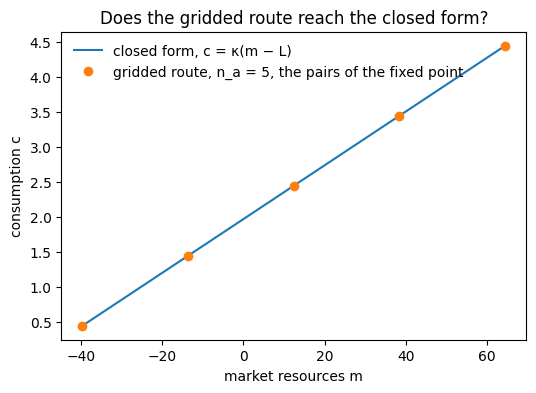

In [29]:
five = check.comparison(5, -40.0, 60.0, resources)
span = np.linspace(five.route.knots[0], five.route.knots[-1], 201)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(span, form.consumption(span), label="closed form, c = κ(m − L)")
ax.plot(five.route.knots, five.route.consumption, "o", label="gridded route, n_a = 5, the pairs of the fixed point")
ax.set_title("Does the gridded route reach the closed form?")
ax.set_xlabel("market resources m"); ax.set_ylabel("consumption c"); ax.legend(frameon=False)
plt.show()

## Interpolation of the value function

The value function is not linear, so its interpolation tests the evaluators. The decision value and the arrival value of the closed form are sampled at 5, 50 and 500 equally spaced nodes on $[-30, 50]$ and represented by the module's Linear and PCHIP evaluators; the largest error is taken on a fixed sample of 1,000 points between the nodes, each of which is interpolated. The errors fall at each refinement, and Linear stays within $\Delta^2 \max|v''|/8$, $\Delta$ the node spacing, up to a rounding allowance of 64 machine epsilons of the largest value.

In [30]:
print(f"{'family':<8} {'nodes':>6} {'value':<9} {'largest error':>14} {'Linear bound':>13}")
for word in ("Linear", "pchip"):
    for count in (5, 50, 500):
        found = check.value_interpolation(closed, word, count)
        for name in ("decision", "arrival"):
            row = getattr(found, name)
            print(f"{word:<8} {count:>6} {name:<9} {row.error:>14.3e} {row.bound:>13.3e}")

family    nodes value      largest error  Linear bound
Linear        5 decision       2.602e+00     7.299e+00
Linear        5 arrival        2.502e+00     7.019e+00
Linear       50 decision       4.346e-02     4.864e-02
Linear       50 arrival        4.179e-02     4.677e-02
Linear      500 decision       4.431e-04     4.690e-04
Linear      500 arrival        4.260e-04     4.510e-04
pchip         5 decision       1.203e+00     7.299e+00
pchip         5 arrival        1.157e+00     7.019e+00
pchip        50 decision       3.548e-03     4.864e-02
pchip        50 arrival        3.412e-03     4.677e-02
pchip       500 decision       4.114e-06     4.690e-04
pchip       500 arrival        3.956e-06     4.510e-04


## Near the borrowing limit

On total wealth from $10^{-3}$ to $1$ the converged policy is compared with the closed form, with the exact compiled values: relative policy error and relative Euler residual below $10^{-8}$, Bellman residual scaled by $1 + |v(m)|$ below $10^{-10}$. The grid of savings of this route starts $10^{-4}$ above the natural borrowing limit and ends $2$ above it, fifty points, so that every point compared, and the next decision state of each, lies between its pairs and is interpolated.

In [31]:
near_stage = check.gridded_stage(50, form.limit + 1e-4, form.limit + 2.0)

In [32]:
near_route = check.gridded_route(near_stage)
near = check.near_limit(closed, near_route, np.geomspace(1e-3, 1.0, 61))
print(f"{near_route.iterations} iterations; relative policy error {near.policy_error:.1e}; "
      f"relative Euler residual {near.euler:.1e}; scaled Bellman residual {near.bellman:.1e}; "
      f"{near.interpolated} points interpolated, {near.extrapolated} extended")

556 iterations; relative policy error 4.7e-10; relative Euler residual 3.5e-11; scaled Bellman residual 5.5e-12; 61 points interpolated, 0 extended


## Human wealth from terminal data

Only the separate compiled human-wealth equations are evaluated here. The terminal value is zero. This comparison computes no finite-horizon consumption policy: under the authored strict inequality, the last-period consumption problem need not attain its supremum.


In [33]:
import math
inputs = {"V[>]": lambda a: 0.0, "h[>]": 0.0}
print(gridded.check_inputs(inputs))
decision = gridded.builder["cntn", "dcsn"].kernels(inputs=inputs)
arrival = gridded.builder["dcsn", "arvl"].kernels(inputs=inputs)
wealth = check.output_function(decision, "Aggregation", "h")
discounted = check.output_function(arrival, "Aggregation", "h")
ratio = check.parameters(gridded)["Γ"] / check.parameters(gridded)["R"]
errors = []
for remaining in range(2001):
    gridded.check_inputs(inputs)
    h = float(wealth(**{"h≻": inputs["h[>]"]}))
    inputs["h[>]"] = float(discounted(h=h))
    errors.append(abs(h - math.fsum(ratio**j for j in range(remaining + 1))))
    if remaining in (0, 1, 10, 100, 500, 2000):
        print(f"{remaining:4d} periods remaining: h={h:.10f}; L={1-h:.10f}")
# Accumulated double-precision rounding over 2,001 affine steps.
assert max(errors) < 2e-12
print(f"maximum difference from the finite sum: {max(errors):.2e}")


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)
   0 periods remaining: h=1.0000000000; L=0.0000000000
   1 periods remaining: h=1.9807692308; L=-0.9807692308
  10 periods remaining: h=10.0010434405; L=-9.0010434405
 100 periods remaining: h=44.6843415286; L=-43.6843415286
 500 periods remaining: h=51.9969026776; L=-50.9969026776


2000 periods remaining: h=52.0000000000; L=-51.0000000000


maximum difference from the finite sum: 2.20e-13


## A finite grid step

`gridded_step` takes a continuation value, its derivative and finite human wealth. It applies one endogenous-grid step even when `Γ ≥ R`. The value below is a real CRRA function on `a > -2`, with its analytic derivative. This is not a stationary solution. `gridded_route` retains its stationary interpretation and requires `Γ < R`.


In [34]:
values = {**check.parameters(gridded), "Γ": 1.05}
finite = check.gridded_stage(50, 0.0, 60.0, {"calibration": values})
finite_inputs = {"V[>]": lambda a: -1/(a+2), "h[>]": 2.0}
finite_step = check.gridded_step(finite, finite_inputs, lambda a: (a+2)**-2)
assert finite_step.h == 3.0
assert np.all(finite_step.consumption < finite_step.knots + 2)
print(f"decision wealth {finite_step.h}; wealth sent backward {finite_step.sent_h}")
finite_step.input_conditions


decision wealth 3.0; wealth sent backward 3.028846153846154


(Condition(condition='continuation-input', entries=(Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='V', owner=None, subjects=(), occurrence=None, mark=None), Named(name='ℝ'), Identity(kind='field', stage='perfect_foresight', address=None, perch='cntn', field='a', owner=None, subjects=(), occurrence=None, mark=None)), status='required', evidence=(), explanation='The representing function for V[>] must be measurable on its declared domain, depend only on (a) in that order, and take values in ℝ.'),)

### Observation

### Decision